# Used Car Price Prediction — Multiple Linear Regression

**Goal:** Predict the resale (`selling_price`) of used cars listed on CarDekho, using vehicle attributes such as age, kilometers driven, mileage, engine size, power, brand, fuel type and transmission type.

**Dataset:** [CarDekho Used Car Dataset](https://www.kaggle.com/datasets/manishkr1754/cardekho-used-car-data) — ~15,400 listings, 14 columns.

**Approach**
1. Exploratory Data Analysis (EDA) — consistency, nulls, duplicates, target distribution
2. Feature engineering & preprocessing (categorical encoding via ColumnTransformer)
3. Baseline model: Multiple Linear Regression (MLR)
4. Regularized comparison: Lasso Regression
5. Evaluation on train **and** test sets (MAE, R²), with an honest discussion of where the model struggles and why

**Key techniques demonstrated:** train/test split discipline (fit only on train, no leakage), pipelines with **ColumnTransformer**, count encoding for high-cardinality categoricals, model evaluation, and diagnosing skewed-target regression problems.

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub

/kaggle/input/datasets/manishkr1754/cardekho-used-car-data/cardekho_dataset.csv


# 1. Load the Dataset

The dataset is provided by Kaggle as a CSV file.

We will use Pandas to read the CSV file into a DataFrame.

A DataFrame is a 2D table containing rows and columns. It allows us to inspect, clean, analyze, and prepare the dataset for machine learning.



In [2]:
df=pd.read_csv("/kaggle/input/datasets/manishkr1754/cardekho-used-car-data/cardekho_dataset.csv")
print("Dataset loaded successfully.")
df.head()

Dataset loaded successfully.


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [3]:
df.shape

(15411, 14)

# 2. Understand the Dataset

Before training an ML model, we need to see what info is available in the dataset.

We will check:

- Consistency
- Column names
- Data types
- Missing/null values
- Duplicate records
- Drop irrelevant columns

This process is called Exploratory Data Analysis (EDA).

## 2.1 Consistency check

We will identify if the categorical features have different numbers of categories.

We will use unique(), nunique() and value_counts()

In [4]:
cols=df.columns

for col in cols:
    print(col)
    print(df[col].unique())
    print(df[col].nunique())
    print()

Unnamed: 0
[    0     1     2 ... 19541 19542 19543]
15411

car_name
['Maruti Alto' 'Hyundai Grand' 'Hyundai i20' 'Ford Ecosport'
 'Maruti Wagon R' 'Hyundai i10' 'Hyundai Venue' 'Maruti Swift'
 'Hyundai Verna' 'Renault Duster' 'Mini Cooper' 'Maruti Ciaz'
 'Mercedes-Benz C-Class' 'Toyota Innova' 'Maruti Baleno'
 'Maruti Swift Dzire' 'Volkswagen Vento' 'Hyundai Creta' 'Honda City'
 'Mahindra Bolero' 'Toyota Fortuner' 'Renault KWID' 'Honda Amaze'
 'Hyundai Santro' 'Mahindra XUV500' 'Mahindra KUV100' 'Maruti Ignis'
 'Datsun RediGO' 'Mahindra Scorpio' 'Mahindra Marazzo' 'Ford Aspire'
 'Ford Figo' 'Maruti Vitara' 'Tata Tiago' 'Volkswagen Polo' 'Kia Seltos'
 'Maruti Celerio' 'Datsun GO' 'BMW 5' 'Honda CR-V' 'Ford Endeavour'
 'Mahindra KUV' 'Honda Jazz' 'BMW 3' 'Audi A4' 'Tata Tigor'
 'Maruti Ertiga' 'Tata Safari' 'Mahindra Thar' 'Tata Hexa'
 'Land Rover Rover' 'Maruti Eeco' 'Audi A6' 'Mercedes-Benz E-Class'
 'Audi Q7' 'BMW Z4' 'BMW 6' 'Jaguar XF' 'BMW X5' 'MG Hector' 'Honda Civic'
 'Isuzu D-M

In [5]:
categorical_columns = [
    "brand",
    "model",
    "seller_type",
    "fuel_type",
    "transmission_type"
]

for column in categorical_columns:
    print(f"\n===== {column} =====")
    print(df[column].value_counts())


===== brand =====
brand
Maruti           4992
Hyundai          2982
Honda            1485
Mahindra         1011
Toyota            793
Ford              790
Volkswagen        620
Renault           536
BMW               439
Tata              430
Mercedes-Benz     337
Skoda             334
Audi              192
Datsun            170
Jaguar             59
Land Rover         51
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus              10
Isuzu               8
Bentley             3
Maserati            2
ISUZU               2
Ferrari             1
Mercedes-AMG        1
Rolls-Royce         1
Force               1
Name: count, dtype: int64

===== model =====
model
i20             906
Swift Dzire     890
Swift           781
Alto            778
City            757
               ... 
Altroz            1
C                 1
Ghost             1
Quattroporte      1
Gurkha            1


## 2.2 Column names check

In [6]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')

## 2.3 Datatype Check using .info()

Numerical columns can usually be used directly by Machine Learning algorithms, while categorical/text columns need to be converted into numerical representations before training.

We will inspect the data types before deciding how to preprocess the data.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


## 2.4 Check Null Values

ML models generally cannot work directly with missing values in the way raw datasets contain them.

We will identify which columns contain missing values before deciding how to handle them.

In [8]:
df.isna().sum()

# No null values, so we can proceed to EDA

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

## 2.5. Check Duplicate Records

Duplicate rows can cause the same car record to appear more than once.

We will count duplicate rows before training the model.

In [9]:
df.duplicated().sum()

np.int64(0)

## 2.6 Dropping Irrelevant Columns

In [10]:
df.drop( columns= ['Unnamed: 0'], inplace=True) # Irrelevant 

# 3. Understanding the Target Variable

**Our goal is to predict `selling_price`**

This is the target variable, also called the dependent variable.

Before training the model, we need to understand how the target values are distributed.

We will:

- **Visualize the target variable**

A numerical summary gives us useful statistics, but a graph can show the distribution more clearly.

We will plot the distribution of selling_price to see:

- where most car prices are concentrated
- whether the distribution is symmetric
- whether there are very expensive outliers

**- Investigate High-Priced Cars**

The target distribution is strongly right skewed.

Before removing or transforming any values, we will inspect the cars with the highest selling prices.

This helps us determine whether the extreme prices are genuine observations or possible data errors.

**- Understand Price Percentiles**

The mean and maximum price can be strongly affected by a small number of expensive cars.

Percentiles help us understand the typical price range of the dataset without being dominated by extreme values.

We will inspect several percentiles of the selling price.

In [11]:
df["selling_price"].describe()

count    1.541100e+04
mean     7.749711e+05
std      8.941284e+05
min      4.000000e+04
25%      3.850000e+05
50%      5.560000e+05
75%      8.250000e+05
max      3.950000e+07
Name: selling_price, dtype: float64

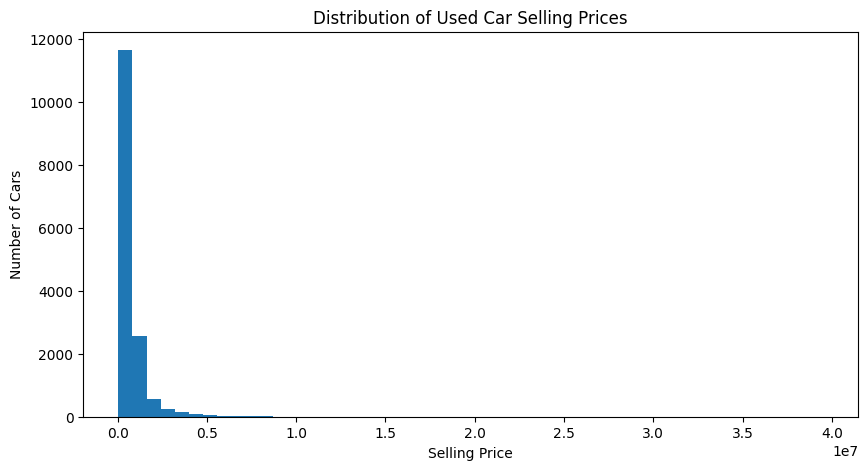

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["selling_price"], bins=50)

plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Used Car Selling Prices")

plt.show()

In [13]:
df.sort_values("selling_price", ascending=False)[
    ["car_name", "brand", "model", "selling_price"]
].head(10)

,car_name,brand,model,selling_price
3799,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,39500000
10969,Rolls-Royce Ghost,Rolls-Royce,Ghost,24200000
1172,Bentley Continental,Bentley,Continental,14500000
9722,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,13000000
9364,Porsche Cayenne,Porsche,Cayenne,11100000
10989,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,11000000
1888,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,11000000
11000,Land Rover Rover,Land Rover,Rover,9200000
8439,BMW 7,BMW,7,8500000
3096,BMW 7,BMW,7,8500000


**Insight : are these extreme prices errors?**

The top 5 rows above (Ferrari, Rolls Royce, Bentley, Mercedes S Class, Porsche) are **genuine luxury-car listings**, they're internally consistent with their brand and model. So we won't drop them as "bad data."

But they *are* extreme outliers relative to the bulk of the dataset (median = 5.6L, while these sit at 1.1–3.95 crore). Ordinary Least Squares regression minimizes *squared* error, which means a handful of these listings can pull the fitted line disproportionately compared to thousands of ordinary cars.

In [14]:
df["selling_price"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

0.25     385000.0
0.50     556000.0
0.75     825000.0
0.90    1375000.0
0.95    2050000.0
0.99    4545000.0
Name: selling_price, dtype: float64

**Insight: percentiles vs the mean**

The 90th percentile (Rupees 13.75L) is less than 3x the median, but the max (3.95 crore) is over 70x the median. That gap between the 90th/95th percentile and the true max confirms the distribution has a **long right tail** driven by a small number of very expensive cars, this is what "right-skewed" looks like in numbers, not just in the histogram shape. A linear model assumes roughly symmetric, constant-variance errors, so this skew is a real modeling concern we'll revisit after the baseline results.

## 3.1 Relationship Between Features and Price (Bivariate Analysis)

So far we've only looked at `selling_price` on its own. Before jumping into modeling, it's worth checking **how each feature relates to price**, this builds intuition for whether a feature is likely to help the model, and surfaces multicollinearity between numeric features before we ever fit anything.

We'll look at:
- a **correlation heatmap** across the numerical features + price
- **price by category** for the three categorical columns (fuel_type, transmission_type, seller_type)
- **price vs. vehicle_age** and **price vs. km_driven** as scatter plots
- **average price by brand**, to see how much of the price spread is just "which brand is it" 

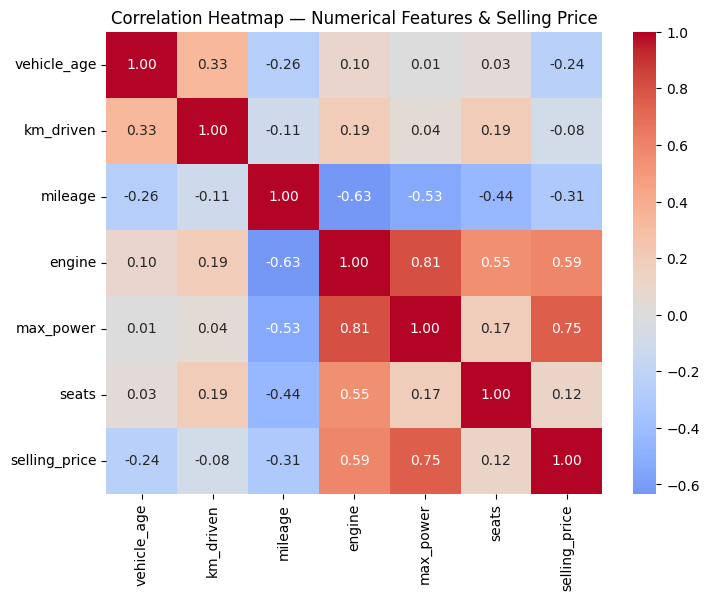

In [15]:
import seaborn as sns

numeric_cols_for_corr = ["vehicle_age", "km_driven", "mileage", "engine", "max_power", "seats", "selling_price"]

corr = df[numeric_cols_for_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Numerical Features & Selling Price")
plt.show()

**What to look for in the heatmap:**
- The column for selling_price shows which numeric features move with price the most (in this domain, max_power and engine are typically the strongest positive correlates, vehicle_age typically the strongest negative one).
- engine and max_power are usually fairly correlated with *each other* too, that's a multicollinearity signal worth flagging.

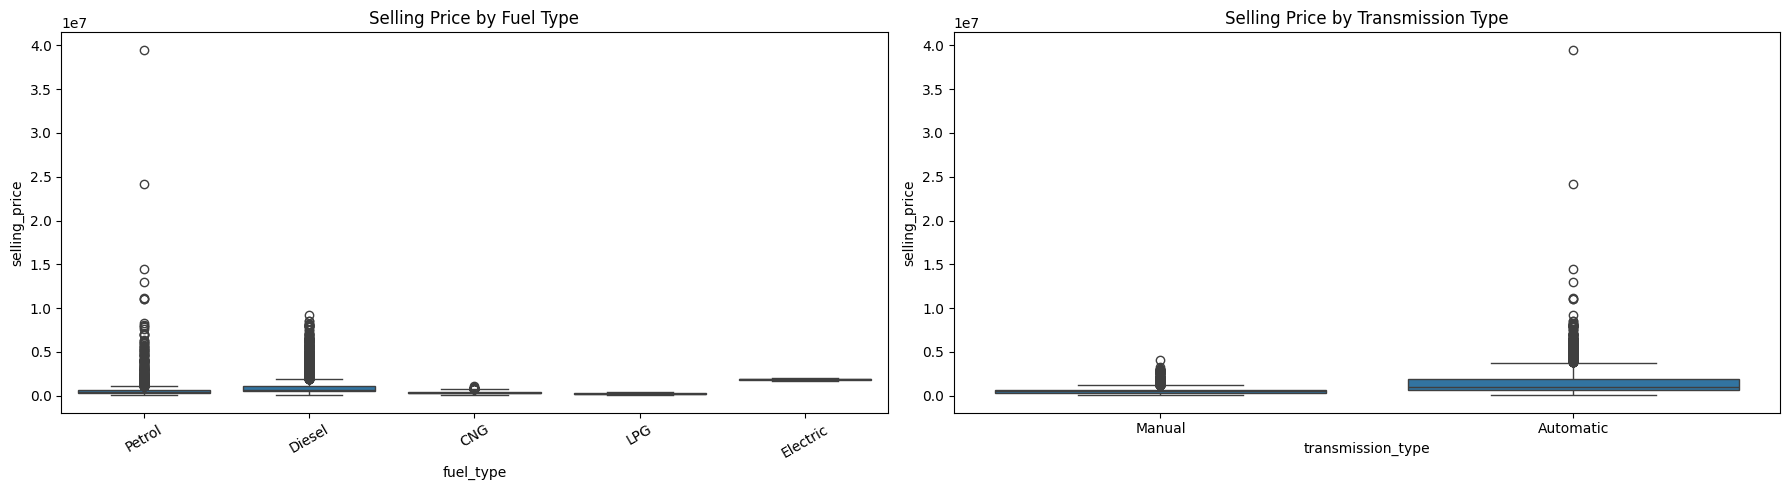

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.boxplot(data=df, x="fuel_type", y="selling_price", ax=axes[0])
axes[0].set_title("Selling Price by Fuel Type")
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x="transmission_type", y="selling_price", ax=axes[1])
axes[1].set_title("Selling Price by Transmission Type")

plt.tight_layout()
plt.show()

**What to look for:**
- **Transmission** — Automatic cars usually sit noticeably higher than Manual in this kind of dataset; if that gap shows up clearly here, it's a useful, easy-to-explain feature.
- **Fuel type** — Diesel/Petrol/CNG/Electric often differ a lot in typical price band (partly because they correlate with vehicle segment, not just fuel itself).


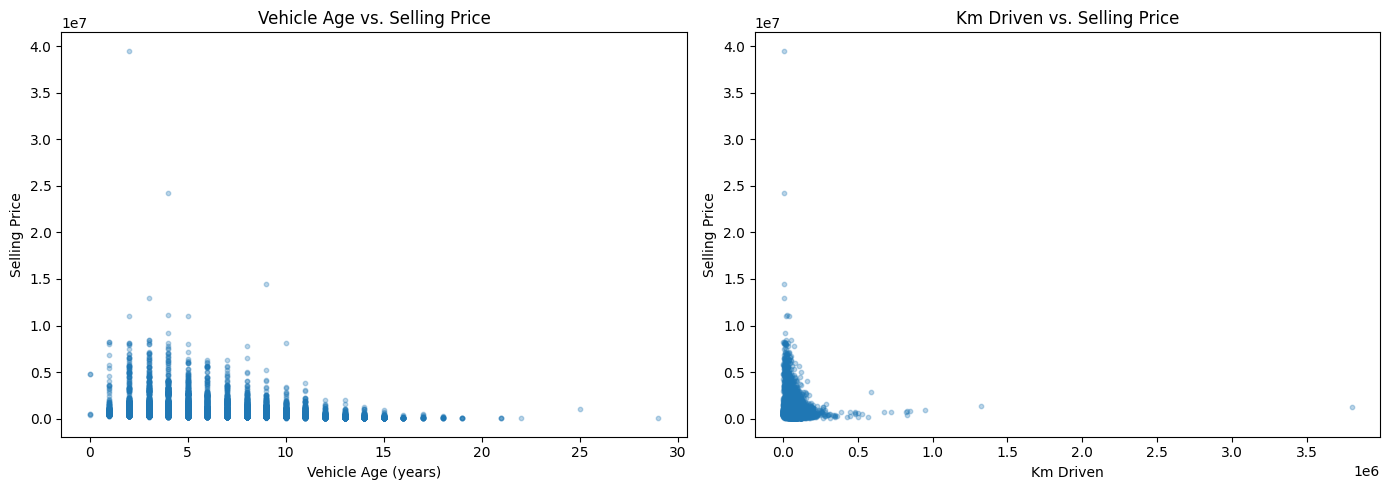

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df["vehicle_age"], df["selling_price"], alpha=0.3, s=10)
axes[0].set_xlabel("Vehicle Age (years)")
axes[0].set_ylabel("Selling Price")
axes[0].set_title("Vehicle Age vs. Selling Price")

axes[1].scatter(df["km_driven"], df["selling_price"], alpha=0.3, s=10)
axes[1].set_xlabel("Km Driven")
axes[1].set_ylabel("Selling Price")
axes[1].set_title("Km Driven vs. Selling Price")

plt.tight_layout()
plt.show()

**What to look for:** 

Both relationships are expected to trend downward (older / more driven cars sell for less), but rarely as a clean straight line — usually a steep drop early (new cars lose value fast) that flattens out for older cars. A linear model captures the average downward trend but not that curve.

A polynomial term or tree-based model would capture that curvature better than plain MLR.

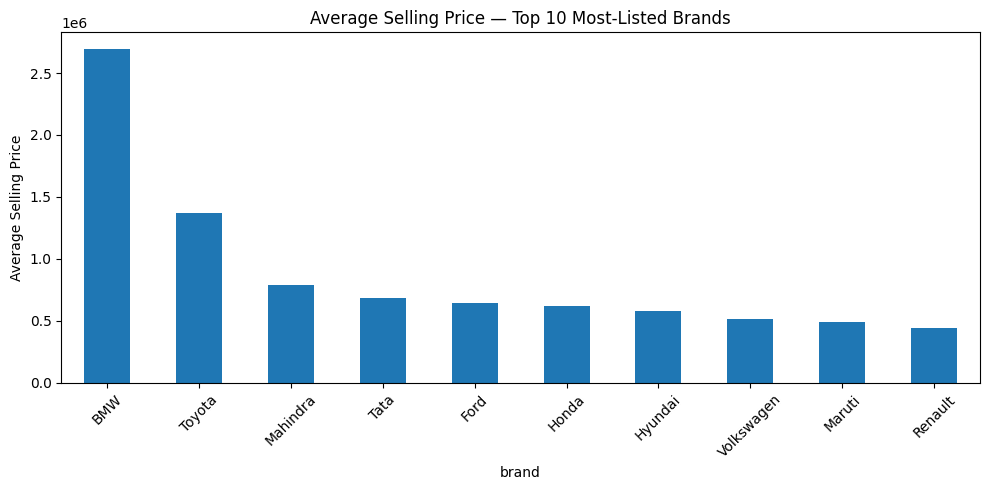

In [18]:
top_brands = df["brand"].value_counts().head(10).index

avg_price_by_brand = (
    df[df["brand"].isin(top_brands)]
    .groupby("brand")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
avg_price_by_brand.plot(kind="bar")
plt.ylabel("Average Selling Price")
plt.title("Average Selling Price — Top 10 Most-Listed Brands")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Why this chart matters:**

Brand (and model) carry a lot of the price signal on their own, a big spread across brands here is part of why we count encode brand/model rather than dropping them.

Note: this uses only the 10 most listed brands for readability ;; luxury brands like Ferrari/Rolls Royce may not appear here since they have very few listings, even though they pull the average price up a lot when they do appear.

# 4. Machine Learning (MLR)
## 4.1 Separate Features and Target

**Our goal is to predict the selling_price of a used car.**

Therefore:

- selling_price is our target variable (y).

- The remaining useful columns are our input features (X).

- The model will learn a relationship between the car's characteristics and its selling price.

**Why drop `car_name` here (and not earlier)?**

car_name is just brand + model concatenated (e.g. "Maruti Alto" = brand ="Maruti" + model="Alto"). Keeping all three means feeding the model duplicate information through a very high cardinality categorical column, which:
- adds noise,redundant columns after encoding,
- makes the learned coefficients harder to interpret (the whole point of choosing MLR over a black box model),
- and doesn't add any signal brand + model don't already provide.

We kept car_name earlier for readable EDA output (e.g. sorting the top 10 priciest cars by name), but we drop it now, right before modeling.

In [19]:
# Inputs -> Remove target and the redundant car_name column
# (car_name duplicates brand + model; dropping it avoids redundant, high cardinality noise)
X = df.drop(columns=["selling_price", "car_name"])

# Y -> target to predict -> Numerical value
y = df["selling_price"]

In [20]:
print(X.head())
print(X.shape)
print()
print(y.head())
print(y.shape)

     brand     model  vehicle_age  km_driven seller_type fuel_type  \
0   Maruti      Alto            9     120000  Individual    Petrol   
1  Hyundai     Grand            5      20000  Individual    Petrol   
2  Hyundai       i20           11      60000  Individual    Petrol   
3   Maruti      Alto            9      37000  Individual    Petrol   
4     Ford  Ecosport            6      30000      Dealer    Diesel   

  transmission_type  mileage  engine  max_power  seats  
0            Manual    19.70     796      46.30      5  
1            Manual    18.90    1197      82.00      5  
2            Manual    17.00    1197      80.00      5  
3            Manual    20.92     998      67.10      5  
4            Manual    22.77    1498      98.59      5  
(15411, 11)

0    120000
1    550000
2    215000
3    226000
4    570000
Name: selling_price, dtype: int64
(15411,)


## 4.2. Split the data into training and testing part

* Before training the ML model, we divide our dataset into two parts:

- Training data → used to teach the model.

- Testing data → used to evaluate the model on unseen data.

- We will use 80% of the data for training and 20% for testing.

- The target variable is selling_price.

The features are stored in X and the target is stored in y.

Important:

The preprocessing steps must be learned from the training data only.

This helps prevent data leakage from the test set.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42 )

print(X_train.shape)
print(X_train.head())
print()

(12328, 11)
               brand  model  vehicle_age  km_driven seller_type fuel_type  \
11210          Volvo   XC60            7      70252      Dealer    Diesel   
1347            Tata  Tiago            2      10000  Individual    Petrol   
10363  Mercedes-Benz    CLS            2       6000      Dealer    Diesel   
316            Honda   City            7      63000      Dealer    Petrol   
10638        Hyundai    i10           10      80292      Dealer    Petrol   

      transmission_type  mileage  engine  max_power  seats  
11210         Automatic    11.20    2400      215.0      5  
1347             Manual    23.84    1199       84.0      5  
10363         Automatic    19.00    1950      241.3      5  
316              Manual    17.80    1497      117.3      5  
10638            Manual    20.36    1197       78.9      5  



## 4.3 Inspect the Model Features
Before encoding categorical variables, we will separate the features into:

- Numerical features
- Categorical features
  
This is important because different types of data require different preprocessing.

- Numerical values can generally be used directly by many machine-learning models.

- Categorical values such as brand, fuel_type, and transmission_type must be converted into a numerical representation.

In [22]:
num_cols = X.select_dtypes(include="number").columns.to_list()
print("Numerical cols are: ", num_cols)
print()
cat_cols = X.select_dtypes(include="object").columns.to_list()
print("Categorical cols are: ", cat_cols)

Numerical cols are:  ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

Categorical cols are:  ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']


## 4.4 Build the Preprocessing Pipeline

- Our dataset contains both numerical and categorical features.
- **Numerical features** → StandardScaler, required for regularized models like Lasso to treat features fairly, and doesn't hurt plain linear regression.
- **Categorical features** → CountEncoder (replaces each category with its frequency count), **then scaled down** so its numeric range doesn't dominate the truly numerical columns.
- We create a Scaler and Encoder and integrate them into separate pipelines.
- Then, merge the two pipelines while adding the num_cols and cat_cols data, Hence making a single pipeline.

**Why CountEncoder instead of one-hot encoding?**

Several categorical columns here (brand, model) are high cardinality. One hot encoding would create a very wide, sparse feature matrix; count encoding keeps things compact and still gives the model a numeric signal correlated with how common/rare a brand or model is. 

In [23]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

sc

StandardScaler()

In [24]:
# Option 2: Import with an alias (common convention)
import category_encoders as ce
encoder = ce.CountEncoder()

encoder

CountEncoder(combine_min_nan_groups=True)

In [25]:
from sklearn.pipeline import Pipeline

# Entire sc scaler is passed here to this pipeline using this function
num_pipeline = Pipeline([
    ('numerical', sc )
])

num_pipeline

Pipeline(steps=[('numerical', StandardScaler())])

In [26]:
# Entire ce encoder is passed here to this pipeline using this function
cat_pipeline = Pipeline([
    ('categorical', encoder)
])
cat_pipeline

Pipeline(steps=[('categorical', CountEncoder(combine_min_nan_groups=True))])

In [27]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('numerical',
                                                  StandardScaler())]),
                                 ['vehicle_age', 'km_driven', 'mileage',
                                  'engine', 'max_power', 'seats']),
                                ('cat',
                                 Pipeline(steps=[('categorical',
                                                  CountEncoder(combine_min_nan_groups=True))]),
                                 ['brand', 'model', 'seller_type', 'fuel_type',
                                  'transmission_type'])])

## 4.5 Understand Fit and Transform

This step takes the raw X_train, applies the preprocessing defined above, and converts it into a fully numerical DataFrame the model can use.

- **fit()** → *learns* preprocessing parameters (e.g. the mean/std for scaling, the category counts for encoding) — **from the training data only**.
- **transform()** → applies those already learned parameters to convert data.
- **fit_transform()** → does both, in one call, on the training data.

```
                 X_train                              X_test
                    │                                     │
                    ▼                                     ▼
              fit_transform()                        transform()
           ┌────────┴────────┐                             │
           │                 │                             │
         FIT             TRANSFORM                    TRANSFORM
           │                 │                             │
           └────────┬────────┘                             │
                     ▼                                      ▼
             X_train_transformed                  X_test_transformed
```

**Why this matters:** if we called preprocessor.fit_transform(X_test) instead of preprocessor.transform(X_test), the encoder/scaler would *relearn* its parameters from the test set ; leaking test set information into preprocessing. The rule: **fit once, on training data only; transform everything else with that same fitted preprocessor.**

However, during machine-learning training we must be careful about where fit() is performed. We should learn preprocessing information from the training data and then use that learned preprocessing on the test data.

This prevents information from the test set from leaking into the training process.

- The fit() operation taught the encoder which categories exist.

- Now we will use transform() to convert the categories into numerical values.

In [28]:
X_transformed = preprocessor.fit_transform(X_train)

X_transformed = pd.DataFrame(
    X_transformed,  # This is the actual transformed numerical data
    columns=preprocessor.get_feature_names_out(), # This gives names to the transformed columns.
                                                  # This is especially useful after One-Hot Encoding.
    index=X_train.index   # This preserves the original row indexes.
)

X_transformed.head()

,num__vehicle_age,num__km_driven,num__mileage,num__engine,num__max_power,num__seats,cat__brand,cat__model,cat__seller_type,cat__fuel_type,cat__transmission_type
11210,0.323969,0.349100,-2.050819,1.756765,2.681685,-0.403824,17.0,5.0,7646.0,5944.0,2512.0
1347,-1.337798,-1.069394,0.985661,-0.547081,-0.382744,-0.403824,340.0,123.0,4542.0,6111.0,9816.0
10363,-1.337798,-1.163564,-0.177042,0.893542,3.296910,-0.403824,257.0,8.0,7646.0,5944.0,2512.0
316,0.323969,0.178369,-0.465315,0.024564,0.396229,-0.403824,1179.0,605.0,7646.0,6111.0,9816.0
10638,1.321030,0.585469,0.149668,-0.550917,-0.502047,-0.403824,2415.0,332.0,7646.0,6111.0,9816.0


In [29]:
# X_transformed = preprocessor.fit_transform(X_train)
# That's correct for training data.

# But when you transform your test data, DO NOT do this:
# X_test_transformed = preprocessor.fit_transform(X_test)

# Instead:
# X_test_transformed = preprocessor.transform(X_test)

# Why?
# Because the preprocessor should learn only from training data.

# If we fit_transform() on the test set, you're allowing the preprocessing step to learn information from your test data. 
# That's a form of data leakage.

In [30]:
X_train.columns

Index(['brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats'],
      dtype='object')

In [31]:
# We can also do this instead:

cat_pipeline = Pipeline([
    ('categorical', encoder),
    ('scaler', sc)
])
cat_pipeline

Pipeline(steps=[('categorical', CountEncoder(combine_min_nan_groups=True)),
                ('scaler', StandardScaler())])

In [32]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('numerical',
                                                  StandardScaler())]),
                                 ['vehicle_age', 'km_driven', 'mileage',
                                  'engine', 'max_power', 'seats']),
                                ('cat',
                                 Pipeline(steps=[('categorical',
                                                  CountEncoder(combine_min_nan_groups=True)),
                                                 ('scaler', StandardScaler())]),
                                 ['brand', 'model', 'seller_type', 'fuel_type',
                                  'transmission_type'])])

## 4.6 Model Instance

* Our selected machine learning algorithm is Multi Linear Regression.
* In this project, the model will learn the relationship between the car's features and its selling_price.
* random_state=42 makes the model's random behavior reproducible.

In [33]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

lin_reg

LinearRegression()

## 4.7 Integrating model with pipeline

In [34]:
lin_reg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ('model', lin_reg)
])

lin_reg_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('numerical',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats']),
                                                 ('cat',
                                                  Pipeline(steps=[('categorical',
                                                                   CountEncoder(combine_min_nan_groups=True)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('model', LinearRegression())])

## 4.8 Train the Multi-Linear Regression Model

The model has now been created, but it has not learned anything yet.

Training happens when we call fit().

We provide:

- the processed training features
- the correct selling prices for those training records
The model uses these examples to learn patterns between the car's characteristics and its selling price.

The model is trained only on the training data.

We do not use x_test or y_test for training.

In [35]:
lin_reg_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('numerical',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats']),
                                                 ('cat',
                                                  Pipeline(steps=[('categorical',
                                                                   CountEncoder(combine_min_nan_groups=True)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('model', LinearRegression())])

## 4.9 Make Predictions on the Test Data

The model has now been trained using the training data.

We can use the trained model to predict selling prices for the test dataset.

The test features were not used during model training.

This gives us an unbiased set of predictions that we can later compare with the actual selling prices.

In [36]:
y_train_pred = lin_reg_pipeline.predict(X_train) # this is for calculating mae_tr
y_test_pred  = lin_reg_pipeline.predict(X_test)
print("Number of predictions:", len(y_test_pred))
print("First 10 predictions:")
print(y_test_pred[:10])

Number of predictions: 3083
First 10 predictions:
[  -5616.20742062  604992.88148572  530346.92341392 1477749.95836976
 -410106.89069062 1043655.34448338  418520.38865636  226795.73666733
  706282.47317013 1761733.717127  ]


## 4.10 Compare Actual and Predicted Prices

In [37]:
y_combined = pd.DataFrame({
    'y_actual': np.asarray(y_test).ravel(),
    'y_predicted': np.asarray(y_test_pred).ravel()
})

y_combined.head(10)

,y_actual,y_predicted
0,190000,-5.616207e+03
1,600000,6.049929e+05
2,665000,5.303469e+05
3,1570000,1.477750e+06
4,160000,-4.101069e+05
5,675000,1.043655e+06
6,465000,4.185204e+05
7,260000,2.267957e+05
8,300000,7.062825e+05
9,850000,1.761734e+06


**Insight: why isnt y_actual equal to y_predicted?**

It shouldnt be ; and if it were, that would actually be a red flag (severe overfitting or a data leak), not a good sign.

Linear regression fits one global equation that minimizes the *average* error across all training cars — it doesn't memorize individual prices. Any single car's real price also depends on things this dataset doesn't capture: condition, accident history, negotiation, regional demand, seller urgency, color, etc. So row-by-row differences between actual and predicted price are expected; what matters is the *aggregate* error, measured by MAE and R² below.

**Also worth flagging:** ifwe  inspect the raw predictions, a few come out **negative** for genuinely cheap cars: An impossible price a linear model has no built in way to prevent. This is a direct symptom of the right skewed target: a handful of very expensive cars pull the fitted line in a way that distorts predictions at the cheap end. 

Log transforming the target is the standard fix for this.

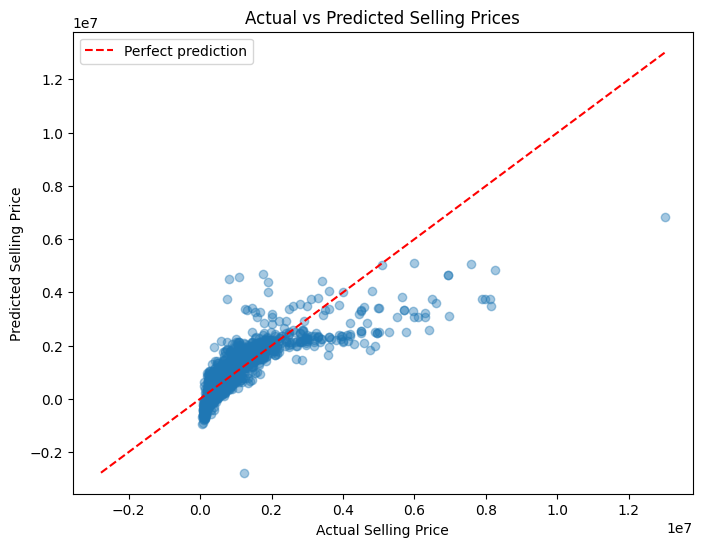

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.4)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Prices")

# Perfect prediction reference line
min_price = min(y_test.min(), y_test_pred.min())
max_price = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.legend()
plt.show()

**What to look for in this plot:**

* Points below the dashed line are over predicted, points above are under predicted.
* Watch for two patterns specifically;
  
   (1) points fanning out wider at higher actual prices, meaning the model is *less* accurate on expensive cars, a classic sign of heteroscedasticity that log transforming price tends to fix;
  
   (2) any points sitting near or below the y=0 predicted line , those are the negative price predictions and this plot makes them visually obvious in a way the table doesn't.

## 4.11 Evaluate on Train and Test

We deliberately compute metrics on **both** sets:
- **Train metrics** tell us how well the model fits the data it learned from.
- **Test metrics** tell us how well it generalizes to unseen cars, this is the number that actually matters.

A large gap where train performance is much better than test usually signals overfitting. (An earlier version of this notebook accidentally compared `y_train` against test-set predictions — a shape mismatch that produces meaningless numbers. Fixed below: predictions are generated separately for train and test, and each is compared against its own true labels.)

In [39]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mae_tr = mean_absolute_error(y_train, y_train_pred)
mae_te = mean_absolute_error(y_test, y_test_pred)

r2_score_tr = r2_score(y_train, y_train_pred)
r2_score_te = r2_score(y_test, y_test_pred)

print(f"Train MAE: {mae_tr:,.0f}  |  Test MAE: {mae_te:,.0f}")
print(f"Train R²:  {r2_score_tr:.3f}  |  Test R²:  {r2_score_te:.3f}")

Train MAE: 263,490  |  Test MAE: 274,064
Train R²:  0.625  |  Test R²:  0.670


1. **R² = 0.62–0.72 means the model explains roughly two-thirds of the variance in price** — a reasonable *baseline*, not a finished product. MAE of ~260K against a median price of 556K means the average error is close to half the typical car's price, theres real room to improve.
   
2. **Test R² came out higher than Train R²**, which is unusual (normally training fits at least as well as testing). On a dataset this size (15K rows) with a heavily right skewed target, this is most plausibly **split variance**: whichever fold happens to contain more of the extreme high-price outliers will look worse.

In [40]:
# r2 scores judgements!
# moderate predictive/explanatory power

# slr, mlr!, poly regr!

# lasso and ridge !

## 4.12 Comparing Against a Regularized Model (Lasso)

Since MLR fits every feature with no penalty on coefficient size, it can lean heavily on individual features, which can overfit. 

**Lasso Regression** adds an L1 penalty that shrinks less useful coefficients toward zero, which can help when we suspect some encoded features (especially the count-encoded, high-cardinality model column) add mostly noise. We fit it here purely as a comparison baseline, using the same preprocessing pipeline.

Lasso = Least Absolute Shrinkage and Selection Operator

It is basically: 
Linear Regression + L1 regularization

Instead of only minimizing the prediction error, Lasso also adds a penalty for large coefficients but Lasso can make some coefficients exactly 0.

In [41]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("lasso", Lasso(alpha=0.1))
])

lasso_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('numerical',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats']),
                                                 ('cat',
                                                  Pipeline(steps=[('categorical',
                                                                   CountEncoder(combine_min_nan_groups=True)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('lasso', Lasso(alpha=0.1))])

In [42]:
y_train_pred_lasso = lasso_pipeline.predict(X_train)
y_test_pred_lasso = lasso_pipeline.predict(X_test)

r2_tr_lasso = r2_score(y_train, y_train_pred_lasso)
r2_te_lasso = r2_score(y_test, y_test_pred_lasso)

mae_tr_lasso = mean_absolute_error(y_train, y_train_pred_lasso)
mae_te_lasso = mean_absolute_error(y_test, y_test_pred_lasso)

print(f"Lasso — Train MAE: {mae_tr_lasso:,.0f}  |  Test MAE: {mae_te_lasso:,.0f}")
print(f"Lasso — Train R²:  {r2_tr_lasso:.3f}   |  Test R²:  {r2_te_lasso:.3f}")

Lasso — Train MAE: 263,490  |  Test MAE: 274,064
Lasso — Train R²:  0.625   |  Test R²:  0.670


**MLR vs. Lasso**

Compare the printed Lasso R²/MAE against the plain MLR numbers above:
- **Very similar scores** → the features aren't overfitting much in the first place, so regularization isn't buying us anything at alpha=0.1; plain MLR is fine, or a *larger* alpha (or Ridge, which shrinks rather than zeroes coefficients) might be worth trying instead.
- **Lasso noticeably better on test, similar or slightly worse on train** → a sign that MLR was mildly overfitting and the L1 penalty helped generalization, a genuinely useful finding to report.

# 5. Conclusion

- Built an end to end pipeline (EDA → preprocessing → MLR baseline → Lasso comparison) predicting used car selling price from vehicle attributes on the CarDekho dataset (15K listings).
- Identified and removed a redundant feature (car_name, duplicate of brand + model) to keep the model's coefficients meaningful. 
- Diagnosed a right skewed target and outlier luxury listings as the likely cause of the model's negative predictions on cheap cars and the train/test R² gap.

-----------------------------